# Handbook exploration

What the source PDF looks like, so we can decide how to clean, split and retrieve it.

Source: the "Sample PDF handbook" linked from the take-home instructions (a Box shared link).
Tokens are counted with tiktoken's `cl100k_base` as a proxy; Claude's tokenizer gives somewhat different numbers.

In [1]:
import collections
import hashlib
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
import requests
import tiktoken
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
PDF_PATH = DATA / "handbook.pdf"
HANDBOOK_URL = "https://paradigmiq.box.com/shared/static/grn1axnqf50npquo07x8r6yojb29g47l.pdf"
EXPECTED_SHA256 = "0f81a75f987ef19e5fd18d85e1a07aa6bd7691a72a5723008f208c7cab7e2a57"

pd.set_option("display.max_colwidth", 120)
enc = tiktoken.get_encoding("cl100k_base")


def n_tokens(text: str) -> int:
    return len(enc.encode(text, disallowed_special=()))

## 1. Download

In [2]:
if not PDF_PATH.exists():
    DATA.mkdir(exist_ok=True)
    resp = requests.get(HANDBOOK_URL, timeout=120)
    resp.raise_for_status()
    PDF_PATH.write_bytes(resp.content)

sha = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()
print(f"{PDF_PATH.stat().st_size / 1e6:.1f} MB, sha256 matches: {sha == EXPECTED_SHA256}")

doc = pymupdf.open(PDF_PATH)
print("pages:", doc.page_count)
print({k: v for k, v in doc.metadata.items() if v})
print("PDF outline / bookmarks:", len(doc.get_toc()))

49.6 MB, sha256 matches: True
pages: 1076
{'format': 'PDF 1.4', 'title': 'PostHog handbook', 'creator': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) HeadlessChrome/146.0.0.0 Safari/537.36', 'producer': 'Skia/PDF m146', 'creationDate': "D:20260420234935+00'00'", 'modDate': "D:20260420234935+00'00'"}
PDF outline / bookmarks: 0


## 2. Images

Extract each unique image (downscaled to at most 1600 px on the long side) with the article it sits in
and the text right above and below it. The index is written to `data/images/index.csv`.

In [3]:
SOURCE_PATH_RE = re.compile(r"^contents/handbook/\S+\.md$")


def source_path_positions(doc):
    """(page_no, y, path) for every article source-path line, in reading order."""
    out = []
    for pno, page in enumerate(doc):
        for x0, y0, x1, y1, text, *_ in page.get_text("blocks"):
            for line in text.splitlines():
                if SOURCE_PATH_RE.match(line.strip()):
                    out.append((pno, y0, line.strip()))
    return out


PATH_POSITIONS = source_path_positions(doc)


def article_at(pno, y):
    """Source path of the article that contains position (page, y)."""
    current = None
    for p, py, path in PATH_POSITIONS:
        if (p, py) <= (pno, y):
            current = path
        else:
            break
    return current


def text_near(page, rect, above=True, max_chars=300):
    blocks = [b for b in page.get_text("blocks") if b[6] == 0]
    if above:
        picked = [b for b in blocks if b[3] <= rect.y0 + 2]
        picked = picked[-3:]
    else:
        picked = [b for b in blocks if b[1] >= rect.y1 - 2]
        picked = picked[:3]
    text = " ".join(b[4].replace("\n", " ").strip() for b in picked)
    return text[-max_chars:] if above else text[:max_chars]


IMG_DIR = DATA / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)
rows, seen = [], set()
for pno, page in enumerate(doc):
    for img in page.get_images(full=True):
        xref = img[0]
        if xref in seen:
            continue
        seen.add(xref)
        info = doc.extract_image(xref)
        rect = page.get_image_rects(xref)[0]
        out = IMG_DIR / f"p{pno + 1:04d}_x{xref}.png"
        if not out.exists():
            pix = pymupdf.Pixmap(doc, xref)
            if pix.n - pix.alpha >= 4:  # CMYK -> RGB
                pix = pymupdf.Pixmap(pymupdf.csRGB, pix)
            im = Image.frombytes("RGBA" if pix.alpha else "RGB", (pix.width, pix.height), pix.samples)
            im.thumbnail((1600, 1600))
            im.save(out)
        rows.append({
            "file": out.name, "page": pno + 1, "xref": xref,
            "width": info["width"], "height": info["height"],
            "article": article_at(pno, rect.y0),
            "text_above": text_near(page, rect, above=True),
            "text_below": text_near(page, rect, above=False),
        })

images = pd.DataFrame(rows)
images.to_csv(IMG_DIR / "index.csv", index=False)
print(len(images), "unique images")
images.groupby("article").size().sort_values(ascending=False).head(15)

77 unique images


article
contents/handbook/engineering/posthog-com/developing-the-website.md       25
contents/handbook/onboarding/metabase-account-analysis.md                 18
contents/handbook/company/brand-assets.md                                  8
contents/handbook/growth/sales/billing.md                                  4
contents/handbook/company/post-mortems/2025-09-29-flags-is-down.md         3
contents/handbook/engineering/operations/support-hero.md                   2
contents/handbook/engineering/operations/incidents.md                      2
contents/handbook/company/post-mortems/2025-11-26-shai-hulud-attack.md     2
contents/handbook/brand/designing-posthog-website.md                       1
contents/handbook/company/new-to-github.md                                 1
contents/handbook/company/culture.md                                       1
contents/handbook/engineering/how-to-access-posthog-cloud-infra.md         1
contents/handbook/content/posthog-style-guide.md                    

A subagent (Claude Sonnet) viewed all 77 images and compared each with its page text. Full results are in
[image_review.md](image_review.md): 5 decorative, 60 informative but already covered by the text, and
12 with information the text lacks. The ones worth captioning:

- p41: a "communication tier list" (pull requests at the top, tapping someone on the shoulder at the
  bottom). The page has no text at all.
- p617: a worked example of the sales commission ramp for someone joining on 21 July.
- p38: what an incorrect logo looks like.

The other gaps are dashboard numbers in a post-mortem, codespace machine sizes, a tool's side panel, and trivia.
I checked p41 and p617 myself and the review is right about both.

## 3. Page header and footer

Chrome's print-to-PDF stamps every page with a header (date/time, "PostHog handbook") and a footer
(`file://` URL, "N/1076"), all in 8 pt Times-Roman at the very top or bottom of the page. No handbook
content uses that font, so it is safe to drop by font + position.

In [4]:
PAGE_HEIGHT = doc[0].rect.height


def is_print_chrome(line) -> bool:
    span = line["spans"][0]
    y = line["bbox"][1]
    return (span["font"] == "Times-Roman" and round(span["size"]) == 8
            and (y < 30 or y > PAGE_HEIGHT - 30))


def page_lines(page):
    """Content lines of a page in reading order, with header/footer removed."""
    for block in page.get_text("dict")["blocks"]:
        for line in block.get("lines", []):
            text = "".join(s["text"] for s in line["spans"])
            if not text.strip() or is_print_chrome(line):
                continue
            span = line["spans"][0]
            yield {"text": text, "size": round(span["size"], 1), "font": span["font"], "y": line["bbox"][1]}


chrome_per_page = collections.Counter()
chrome_texts = collections.Counter()
for page in doc:
    for block in page.get_text("dict")["blocks"]:
        for line in block.get("lines", []):
            if is_print_chrome(line):
                chrome_per_page[page.number] += 1
                text = "".join(s["text"] for s in line["spans"]).strip()
                chrome_texts[re.sub(r"^\d+/1076$", "N/1076", text)] += 1

print("header/footer lines per page:", collections.Counter(chrome_per_page.values()))
print(dict(chrome_texts))

header/footer lines per page: Counter({4: 1076})
{'4/20/26, 4:49 PM': 1076, 'PostHog handbook': 1076, 'file:///tmp/handbook-pdf-build/handbook.html': 1076, 'N/1076': 1076}


## 4. Structure: is it just a collection of articles?

Each line gets a role from its font:

| font | role |
|---|---|
| HelveticaNeue-Bold 22 pt | article title (the very first one is the document title) |
| Menlo-Regular 8.5 pt, `contents/handbook/...md` | article source path, right under the title |
| HelveticaNeue-Bold 15 / 12.5 / 11 pt | H2 / H3 / H4 headings |
| HelveticaNeue-Bold, smaller | minor headings inside tables and callouts |
| everything else | body text, tables, code |

In [5]:
font_survey = collections.Counter((l["font"], l["size"]) for page in doc for l in page_lines(page))
pd.DataFrame([{"font": f, "size": s, "lines": n} for (f, s), n in font_survey.items()]) \
    .sort_values(["size", "lines"], ascending=False).head(15)

,font,size,lines
0,HelveticaNeue-Bold,22.0,281
7,HelveticaNeue-Bold,15.0,1110
15,TimesNewRomanPSMT,15.0,13
4,HelveticaNeue-Bold,12.5,1216
3,Georgia,11.0,20846
5,Georgia-Bold,11.0,2120
9,HelveticaNeue-Bold,11.0,313
8,Georgia-Italic,11.0,116
18,Type3 (155 0 R),11.0,30
24,Georgia-BoldItalic,11.0,4


In [6]:
HEADING_SIZES = {22.0: "title", 15.0: "h2", 12.5: "h3", 11.0: "h4"}


def line_role(line) -> str:
    if line["font"] == "Menlo-Regular" and line["size"] == 8.5 and SOURCE_PATH_RE.match(line["text"].strip()):
        return "path"
    if line["font"] == "HelveticaNeue-Bold":
        return HEADING_SIZES.get(line["size"], "h5")
    return "body"


lines = [{**line, "page": page.number + 1, "role": line_role(line)}
         for page in doc for line in page_lines(page)]
# Page 1 opens with the document title in the same font as article titles; keep it out of the first article.
if lines[0]["text"].strip() == doc.metadata["title"]:
    lines[0]["role"] = "doc_title"

# Split into articles at each source path. The title lines just above the path belong to the new article.
front_matter, articles = [], []
current = front_matter
for line in lines:
    if line["role"] == "path":
        title_lines = []
        while current and current[-1]["role"] == "title":
            title_lines.insert(0, current.pop())
        articles.append({"path": line["text"].strip(),
                         "title": " ".join(t["text"].strip() for t in title_lines),
                         "lines": title_lines})
        current = articles[-1]["lines"]
    else:
        current.append(line)

print("lines before the first article:", [l["text"] for l in front_matter])
print("articles:", len(articles), "| unique paths:", len({a["path"] for a in articles}))
print("articles without a title:", [a["path"] for a in articles if not a["title"]])
print("first article title:", repr(articles[0]["title"]))
print("titles wrapping onto 2+ lines:", sum(sum(l["role"] == "title" for l in a["lines"]) > 1 for a in articles))

starts_new_page = sum(a["lines"][0]["y"] < 120 for a in articles)
print(f"articles starting at the top of a page: {starts_new_page}/{len(articles)}")

folders = [a["path"].split("/")[2] if a["path"].count("/") > 2 else "(root)" for a in articles]
runs = [k for i, k in enumerate(folders) if i == 0 or folders[i - 1] != k]
print("folders appear in", len(runs), "contiguous runs for", len(set(folders)), "folders")

lines before the first article: ['PostHog handbook']
articles: 254 | unique paths: 254
articles without a title: []
first article title: 'Art, brand, and merch requests'
titles wrapping onto 2+ lines: 17
articles starting at the top of a page: 254/254
folders appear in 20 contiguous runs for 16 folders


Does the PDF contain the whole handbook? Compare with the PostHog website repo, pinned to the last commit
before the PDF was generated (2026-04-20 23:49 UTC).

In [7]:
SOURCE_SHA = "ae45b60fa3e7b815867220ac4c1cf41b6d741973"  # posthog.com master at 2026-04-20T20:29Z
tree_cache = DATA / "source_tree.json"
if not tree_cache.exists():
    api = "https://api.github.com/repos/PostHog/posthog.com"
    contents = requests.get(f"{api}/contents/contents?ref={SOURCE_SHA}", timeout=60).json()
    handbook_sha = next(item["sha"] for item in contents if item["name"] == "handbook")
    tree = requests.get(f"{api}/git/trees/{handbook_sha}?recursive=1", timeout=60).json()
    tree_cache.write_text(json.dumps(tree))
tree = json.loads(tree_cache.read_text())

repo_pages = {"contents/handbook/" + t["path"] for t in tree["tree"]
              if t["type"] == "blob" and t["path"].endswith((".md", ".mdx"))}
pdf_pages = {a["path"] for a in articles}
print("truncated tree:", tree["truncated"])
print("handbook pages in repo:", len(repo_pages), "| in PDF:", len(pdf_pages),
      "| in PDF but not repo:", len(pdf_pages - repo_pages))
not_in_pdf = sorted(repo_pages - pdf_pages)
print("in repo but not in PDF:", len(not_in_pdf))
collections.Counter(p.split("/")[2] if p.count("/") > 2 else "(root)" for p in not_in_pdf).most_common()

truncated tree: False
handbook pages in repo: 313 | in PDF: 254 | in PDF but not repo: 0
in repo but not in PDF: 59


[('engineering', 29),
 ('docs-and-wizard', 14),
 ('content', 5),
 ('community', 4),
 ('people', 4),
 ('company', 2),
 ('marketing', 1)]

## 5. Token distribution: articles and headings

Three ways to cut the text, each piece including its own heading:
- **article**: one piece per article.
- **H2 section**: split at every H2. Text before the first H2 is its own "intro" piece.
- **H3 section**: split at every H2 or H3.

In [8]:
def split_sections(article, levels):
    sections, current = [], {"heading": article["title"], "lines": []}
    for line in article["lines"]:
        if line["role"] in levels and current["lines"]:
            sections.append(current)
            current = {"heading": line["text"].strip(), "lines": []}
        current["lines"].append(line)
    sections.append(current)
    return [{"path": article["path"], "heading": s["heading"], "page": s["lines"][0]["page"],
             "text": "\n".join(l["text"] for l in s["lines"])} for s in sections]


units = {
    "article": [s for a in articles for s in split_sections(a, levels=())],
    "H2 section": [s for a in articles for s in split_sections(a, levels=("h2",))],
    "H3 section": [s for a in articles for s in split_sections(a, levels=("h2", "h3"))],
}
for rows in units.values():
    for row in rows:
        row["tokens"] = n_tokens(row["text"])

summary = pd.DataFrame({
    name: pd.Series([r["tokens"] for r in rows]).describe(percentiles=[.1, .25, .5, .75, .9, .99])
    for name, rows in units.items()
}).T.rename(columns={"count": "pieces"})
summary["total"] = [sum(r["tokens"] for r in rows) for rows in units.values()]
summary.astype(int)

,pieces,mean,std,min,10%,25%,50%,75%,90%,99%,max,total
article,254,1613,1439,51,447,678,1168,1899,3328,6497,9628,409809
H2 section,1364,300,392,1,34,86,173,364,666,1909,5976,409577
H3 section,2580,158,165,1,14,58,114,206,342,821,1756,409180


In [9]:
thresholds = [50, 100, 500, 1000, 2000, 4000, 8000]
pd.DataFrame({
    name: {f"< {thresholds[0]}": sum(r["tokens"] < thresholds[0] for r in rows),
           **{f"> {t}": sum(r["tokens"] > t for r in rows) for t in thresholds[1:]}}
    for name, rows in units.items()
}).T

,< 50,> 100,> 500,> 1000,> 2000,> 4000,> 8000
article,0,252,220,147,61,19,1
H2 section,185,958,233,72,12,1,0
H3 section,554,1435,108,11,0,0,0


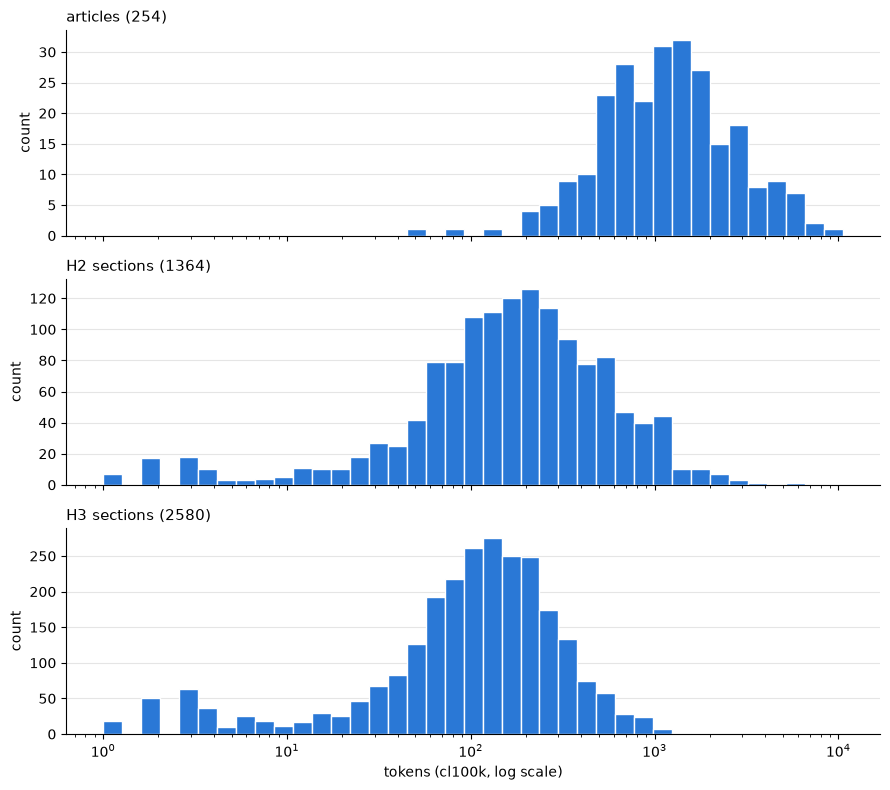

In [10]:
SERIES_BLUE = "#2a78d6"  # dataviz reference palette, categorical slot 1
bins = np.logspace(0, np.log10(max(r["tokens"] for r in units["article"]) * 1.1), 40)
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ax, (name, rows) in zip(axes, units.items()):
    ax.hist([r["tokens"] for r in rows], bins=bins, color=SERIES_BLUE, edgecolor="white", linewidth=1)
    ax.set_xscale("log")
    ax.set_title(f"{name}s ({len(rows)})", loc="left", fontsize=11)
    ax.set_ylabel("count")
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[-1].set_xlabel("tokens (cl100k, log scale)")
fig.tight_layout()

In [11]:
pd.DataFrame(units["article"]).nlargest(10, "tokens")[["path", "page", "tokens"]]

,path,page,tokens
161,contents/handbook/growth/sales/utilization-by-business-type.md,696,9628
167,contents/handbook/growth/use-case-selling/growth-and-marketing.md,756,7084
143,contents/handbook/growth/sales/new-sales.md,618,6625
83,contents/handbook/engineering/operations/support-hero.md,336,6385
69,contents/handbook/engineering/ai/products.md,275,6339
14,contents/handbook/company/communication.md,47,5937
128,contents/handbook/growth/sales/contract-rules.md,524,5880
140,contents/handbook/growth/sales/how-we-work.md,596,5837
130,contents/handbook/growth/sales/crm.md,543,5451
85,contents/handbook/engineering/posthog-com/developing-the-website.md,354,5221


In [12]:
pd.DataFrame(units["H3 section"]).nlargest(10, "tokens")[["path", "heading", "page", "tokens"]]

,path,heading,page,tokens
197,contents/handbook/company/offsites.md,How to plan an offsite in 8 weeks - a checklist,94,1756
1489,contents/handbook/growth/sales/new-sales.md,2. You qualify,619,1735
893,contents/handbook/engineering/posthog-com/developing-the-website.md,Markdown details,369,1527
1450,contents/handbook/growth/sales/how-we-work.md,How commission works - Technical Account Managers,600,1269
188,contents/handbook/company/offsites.md,Small team offsites,89,1231
865,contents/handbook/engineering/operations/support-hero.md,Creating tickets on behalf of users or from existing tickets,345,1202
2180,contents/handbook/people/hiring-process/engineering-hiring.md,Engineering hiring process,918,1199
1490,contents/handbook/growth/sales/new-sales.md,3. First call (30 minutes) - Discovery & initial demo,622,1154
1375,contents/handbook/growth/sales/customer-training.md,Topics to cover,567,1141
1296,contents/handbook/growth/sales/contracts.md,Creating an order form,537,1130


## 6. What the PDF export dropped

The PDF was rendered from the handbook's MDX source, and some components rendered as nothing. Two kinds show up:
- **Blank names and teams.** `<TeamMember name="..."/>` and `<SmallTeam slug="..."/>` render empty, leaving text like
  "handled by , , and on the team".
- **Collapsed sections.** Only the `<summary>` of a `<details>` block is printed; the body is missing.

To measure this, fetch each article's markdown at the pinned commit, then check every source line against
the PDF text. Both sides are reduced to lowercase letters and digits, so punctuation, markup and the blanks
themselves don't affect the match.

In [13]:
SOURCE_DIR = DATA / "source_md"
SOURCE_DIR.mkdir(exist_ok=True)


def source_markdown(path: str) -> str:
    cached = SOURCE_DIR / path.replace("/", "__")
    if not cached.exists():
        url = f"https://raw.githubusercontent.com/PostHog/posthog.com/{SOURCE_SHA}/{path}"
        resp = requests.get(url, timeout=60)
        resp.raise_for_status()
        cached.write_text(resp.text, encoding="utf-8")
    return cached.read_text(encoding="utf-8")


PEOPLE_RE = re.compile(r"<(TeamMember|SmallTeam)\b([^>]*?)/>")


def alnum(text: str) -> str:
    return re.sub(r"[^a-z0-9]", "", text.lower())


def md_line_text(line: str) -> str:
    """What a markdown line should look like as plain text."""
    line = PEOPLE_RE.sub("", line)
    line = re.sub(r"!\[[^\]]*\]\([^)]*\)", "", line)        # images
    line = re.sub(r"\[([^\]]*)\]\([^)]*\)", r"\1", line)    # links -> link text
    line = re.sub(r"</?[A-Za-z][^>]*>", "", line)           # other HTML / JSX tags
    line = re.sub(r"^\s*(#+|[-*+]|\d+\.|>)\s+", "", line)   # heading, list and quote markers
    return line


def source_lines(md: str):
    """(line_no, text, inside_details) for each content line, skipping front matter and comments."""
    md = re.sub(r"\A---\n.*?\n---\n", lambda m: "\n" * m.group(0).count("\n"), md, flags=re.DOTALL)
    md = re.sub(r"<!--.*?-->", lambda m: "\n" * m.group(0).count("\n"), md, flags=re.DOTALL)
    depth = 0
    for no, raw in enumerate(md.splitlines(), 1):
        depth += raw.count("<details") - raw.count("</details>")
        yield no, raw, depth > 0 and "<summary" not in raw


WINDOW = 40  # normalised characters of each line to look for

matches = []
for article in articles:
    md = source_markdown(article["path"])
    # normalised PDF text of this article, with the page of each character offset
    pdf_text, offsets = "", []
    for line in article["lines"]:
        offsets.append((len(pdf_text), line["page"]))
        pdf_text += alnum(line["text"])
    starts = [o for o, _ in offsets]

    cursor = 0
    for no, raw, in_details in source_lines(md):
        key = alnum(md_line_text(raw))[:WINDOW]
        pos = None
        if len(key) >= 15:
            pos = pdf_text.find(key, cursor)
            if pos < 0:
                pos = pdf_text.find(key)
        if pos is not None and pos >= 0:
            cursor = pos
        page = offsets[np.searchsorted(starts, cursor, side="right") - 1][1] if offsets else None
        matches.append({"path": article["path"], "line_no": no, "raw": raw.strip(), "testable": len(key) >= 15,
                        "found": pos is not None and pos >= 0, "page": page, "in_details": in_details})

matches = pd.DataFrame(matches)
testable = matches[matches.testable]
print(f"source lines checked: {len(testable)}, found in PDF: {testable.found.mean():.1%}")
testable.groupby("in_details").found.agg(["size", "mean"]).rename(
    index={False: "normal text", True: "inside <details> body"}, columns={"size": "lines", "mean": "found"})

source lines checked: 15669, found in PDF: 98.5%


,lines,found
in_details,,
normal text,15527,0.993688
inside <details> body,142,0.070423


Missing lines outside `<details>`, by article. These are either other components that didn't render, or
lines the matching gets wrong (e.g. tables, code).

In [14]:
missing = testable[~testable.found & ~testable.in_details]
print(len(missing), "missing lines outside <details>")
missing.groupby("path").size().sort_values(ascending=False).head(15)

98 missing lines outside <details>


path
contents/handbook/engineering/ai/architecture.md                      25
contents/handbook/engineering/ai/products.md                          16
contents/handbook/company/security-advisories.md                       9
contents/handbook/product/releasing-new-products-and-features.md       8
contents/handbook/growth/sales/accounts-overview.md                    6
contents/handbook/engineering/ai/ai-platform.md                        5
contents/handbook/growth/sales/customer-faqs.md                        5
contents/handbook/engineering/development-process.md                   4
contents/handbook/growth/sales/new-hire-onboarding.md                  3
contents/handbook/engineering/cloud-providers.md                       2
contents/handbook/onboarding/onboarding-tracking.md                    2
contents/handbook/engineering/how-to-access-posthog-cloud-infra.md     2
contents/handbook/product/user-feedback.md                             2
contents/handbook/cs-and-onboarding/how-we-wor

In [15]:
missing.sample(20, random_state=0)[["path", "page", "raw"]]

,path,page,raw
7385,contents/handbook/engineering/ai/architecture.md,265,"Tools-->>Agent: Returns actual events:<br/>'user_signed_up', 'account_created'"
24633,contents/handbook/onboarding/onboarding-tracking.md,894,- [[Onboarding Pipeline] 6d. Churned -> set timestamp](https://posthog.vitally-eu.io/settings/playbooks/65d770f0-fe2...
3784,contents/handbook/company/security-advisories.md,142,<strong>Severity:</strong> Low / Medium / Critical<br />
7956,contents/handbook/engineering/ai/products.md,284,LocalExec[Local Execution<br/>Claude Code-like]
13830,contents/handbook/growth/sales/accounts-overview.md,493,"n3 -- ""Organic growth to<br>$2k+ MRR"" --> n14[""Account review<br>(Simon decides)""]"
21207,contents/handbook/growth/use-case-selling/growth-and-marketing.md,759,"| CRO / Growth PM | Growth PM, CRO Specialist, Head of Growth | Conversion rate optimization, experiment velocity, a..."
7322,contents/handbook/engineering/ai/architecture.md,263,PostHogCode[PostHog Code<br/>Desktop App]
17343,contents/handbook/growth/sales/new-hire-onboarding.md,616,"src=""https://res.cloudinary.com/dmukukwp6/image/upload/q_auto,f_auto/shapes_at_26_01_14_12_45_06_b0c13c36a5.png"""
7955,contents/handbook/engineering/ai/products.md,284,LocalRepo[Local Repo<br/>User Filesystem]
13819,contents/handbook/growth/sales/accounts-overview.md,493,"n1[""<b>Manual leads</b><br>- Anyone can create - use your discretion""] --> C"


In [16]:
details = testable[testable.in_details]
dropped_details = (details.groupby("path")
                   .agg(lines=("found", "size"), missing=("found", lambda s: int((~s).sum())),
                        first_page=("page", "min"))
                   .query("missing > 0").sort_values("missing", ascending=False))
print(len(dropped_details), "articles lose text inside collapsed sections")
dropped_details

5 articles lose text inside collapsed sections


,lines,missing,first_page
path,,,
contents/handbook/cs-and-onboarding/customer-industry-segments.md,49,42,202
contents/handbook/onboarding/onboarding-conversations-playbook.md,42,42,882
contents/handbook/marketing/ownership.md,19,19,836
contents/handbook/company/security-advisories.md,17,17,142
contents/handbook/people/onboarding.md,12,12,954


### Pages with blank names and team links

Each `<TeamMember>` / `<SmallTeam>` gets the page of its source line. Status:
- **blank**: the line is in the PDF but the name/team is an empty gap.
- **dropped**: the whole line is missing (usually inside a collapsed section), so there is no gap to see.
- Lines that are *only* components (e.g. a table cell) have no text to match; they inherit the page of the
  nearest line above and count as blank. Their page can be one too early (`page_exact` is False), e.g. the
  support SME list in `support-smes.md` is on p1053 but partly lands on p1052.

In [17]:
mentions = []
for row in matches.itertuples():
    for m in PEOPLE_RE.finditer(row.raw):
        value = re.search(r'(?:name|slug)="([^"]+)"', m.group(2))
        mentions.append({"path": row.path, "page": row.page, "page_exact": bool(row.found), "kind": m.group(1),
                         "value": value.group(1) if value else m.group(2).strip(),
                         "status": "blank" if row.found or not row.testable else "dropped",
                         "source_line": row.raw})
mentions = pd.DataFrame(mentions)
mentions.to_csv(DATA / "blank_mentions.csv", index=False)
print(mentions.groupby(["kind", "status"]).size().unstack(fill_value=0))

blank = mentions[mentions.status == "blank"]
blank_pages = (blank.groupby(["page", "path"])
               .agg(blanks=("value", "size"), exact=("page_exact", "all"),
                    missing=("value", lambda v: ", ".join(dict.fromkeys(v))))
               .reset_index())
print(f"{len(blank)} blank mentions on {blank_pages.page.nunique()} pages")
pd.set_option("display.max_rows", 200)
blank_pages

status      blank  dropped
kind                      
SmallTeam     103        7
TeamMember    113       13
216 blank mentions on 99 pages


,page,path,blanks,exact,missing
0,1,contents/handbook/brand/art-requests.md,4,True,"Lottie Coxon, Heidi Berton, Daniel Hawkins, marketing"
1,3,contents/handbook/brand/designing-posthog-website.md,1,True,website
2,6,contents/handbook/brand/email-comms.md,1,True,marketing
3,9,contents/handbook/brand/email-comms.md,1,True,growth
4,12,contents/handbook/brand/overview.md,3,True,"website, marketing, content"
5,21,contents/handbook/brand/startups.md,2,True,Joe Martin
6,65,contents/handbook/company/goal-setting.md,2,True,"blitzscale, Scott Lewis"
7,73,contents/handbook/company/lore.md,4,True,"James Greenhill, Ben White, Paul D'Ambra, Charles Cook"
8,74,contents/handbook/company/lore.md,5,True,"Marius Andra, Ian Vanagas, James Hawkins, Dylan Martin"
9,79,contents/handbook/company/management.md,1,True,Marius Andra
